## Embeddings: Análisis

- Se interpreta qué estructura capturan los embeddings y cómo se relacionan con las Partes II, IV y V

- Se responden PQ2 (mercados) y PQ3 (sustitutos y afinidades) desde la representación aprendida

- Solo lee las tablas de `a_grafo` … `d_enlaces`: no recalcula embeddings (**local**, segundos)

- **Fuente:** OCDS – OECE (antes OSCE), Portal de Contrataciones Abiertas, licencia **CC BY 4.0**; 2023-2025

### Utilidades

In [1]:
NOTEBOOK = "e_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

Tablas de resultados de cada notebook (`temp/<notebook>/tablas/`)

In [3]:
def tabla(nb, nombre):
    return pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / nombre)

config = leer_config()
perfil = tabla("b_node2vec", "perfil_pq")
estab = tabla("b_node2vec", "estabilidad")
conv = tabla("c_proyeccion", "convergencia")
perfiles_lat = tabla("c_proyeccion", "perfiles_latentes")
res = tabla("d_enlaces", "resultados")
por_tipo = tabla("d_enlaces", "por_tipo_negativo")
prec_top = tabla("d_enlaces", "precision_top")
top_pares = tabla("d_enlaces", "top_pares")
comunidades = cargar_comunidades(pd.read_parquet(datos_dir / "nodos.parquet").clave)
print(f"configuraciones: {len(perfil) - 1} | referencias de convergencia: {conv.referencia.nunique()} | modelos de enlaces: {len(res)}")

Parte V disponible (louvain): 41 comunidades en 7,116 proveedores del núcleo
configuraciones: 10 | referencias de convergencia: 7 | modelos de enlaces: 20


---
### **1. Qué estructura capturan los embeddings**

- **Homofilia:** % de los 10 vecinos del embedding en la misma región o familia UNSPSC

- **Rol:** Spearman entre el grado del nodo y el de sus vecinos (posición estructural)

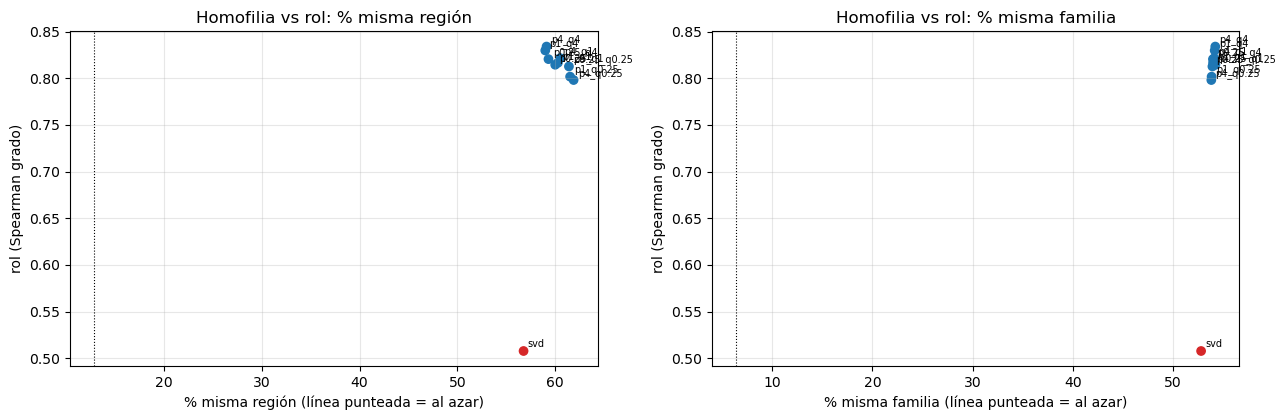

In [4]:
d_ = perfil.set_index("config")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a_, x in zip(ax, ["% misma región", "% misma familia"]):
    sin_azar = d_.drop("al azar")
    a_.scatter(sin_azar[x], sin_azar["rol (Spearman grado)"], c=["tab:red" if c == "svd" else "tab:blue" for c in sin_azar.index])
    for c, r in sin_azar.iterrows():
        a_.annotate(c, (r[x], r["rol (Spearman grado)"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    a_.axvline(d_.loc["al azar", x], color="k", ls=":", lw=.8)
    a_.set(xlabel=f"{x} (línea punteada = al azar)", ylabel="rol (Spearman grado)", title=f"Homofilia vs rol: {x}")
mostrar_fig("homofilia_vs_rol")

- **Los embeddings capturan sobre todo mercado:** ~60% de vecinos de la misma región y ~54% de la misma familia, contra 13% y 6% al azar

- **p y q mueven el equilibrio en la dirección de la teoría** (DFS → región, BFS → rol), pero en un rango estrecho: ~3 puntos de región y 0.03 de rol

- **Por qué p y q pesan tan poco aquí:** la co-participación crea un **clique por proceso**; el vecindario inmediato y la comunidad casi coinciden, y Word2Vec termina viendo los mismos contextos

- **SVD** captura el rubro casi igual (53% familia) pero no la posición estructural (rol 0.51 vs 0.80-0.83)

---
### **2. Convergencia con las partes anteriores**

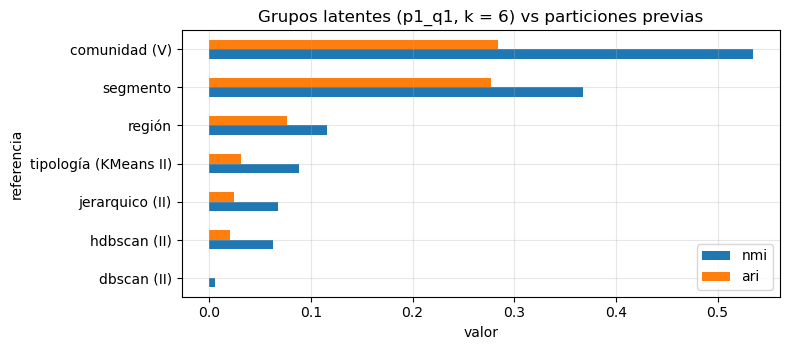

,n,ari,nmi,pureza
referencia,,,,
región,56975,0.077,0.116,0.363
segmento,55238,0.277,0.367,0.457
tipología (KMeans II),11665,0.031,0.088,0.681
dbscan (II),11665,-0.000,0.006,0.976
hdbscan (II),11665,0.021,0.063,0.680
jerarquico (II),4367,0.025,0.068,0.733
comunidad (V),7116,0.284,0.535,0.390


In [5]:
ref = conv[conv.config == config["conf_ref"]].set_index("referencia")[["n", "ari", "nmi", "pureza"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ref[["nmi", "ari"]].sort_values("nmi").plot.barh(ax=ax)
ax.set(xlabel="valor", title=f"Grupos latentes ({config['conf_ref']}, k = {config['k_lat']}) vs particiones previas")
mostrar_fig("convergencia_resumen")
ref.round(3)

In [6]:
if comunidades is not None:
    display(tabla("c_proyeccion", "cruce_v").round(3))

,config,k,nmi,ari,anidamiento
0,p1_q1,6,0.535,0.284,0.833
1,p1_q1,41,0.772,0.576,0.667
2,p0.25_q4,6,0.536,0.283,0.830
3,p0.25_q4,41,0.779,0.585,0.680
4,p4_q0.25,6,0.533,0.286,0.832
5,p4_q0.25,41,0.752,0.524,0.640
6,svd,6,0.531,0.268,0.851
7,svd,41,0.761,0.623,0.748


| Parte | Qué agrupa | Convergencia con el embedding | Lectura |
|---|---|---|---|
| II – Tipologías (KMeans, Ward, HDBSCAN) | **Comportamiento**: tamaño, competencia, dependencia | Baja (NMI 0.06-0.09) | Complementarias: el embedding dice **dónde** compite, la tipología **cómo** |
| II – "Contratistas de obras" | Rubro (`pct_obras`) | Alta: 44% del grupo latente de obras | La única tipología basada en rubro es la que coincide |
| IV – PageRank / HITS | **Peso** en la red de compras | Ortogonal: PageRank se reparte en todos los grupos | Cada mercado tiene sus centrales; HITS marca el núcleo de salud |
| V – Comunidades (Louvain) | **Mercados densos** del núcleo de co-participación | **La más alta:** NMI 0.54 (k = 6) y 0.77 (k = 41); anidamiento 0.83 | Misma estructura por dos caminos; el embedding la extiende a la periferia |

---
### **3. Predicción de enlaces**

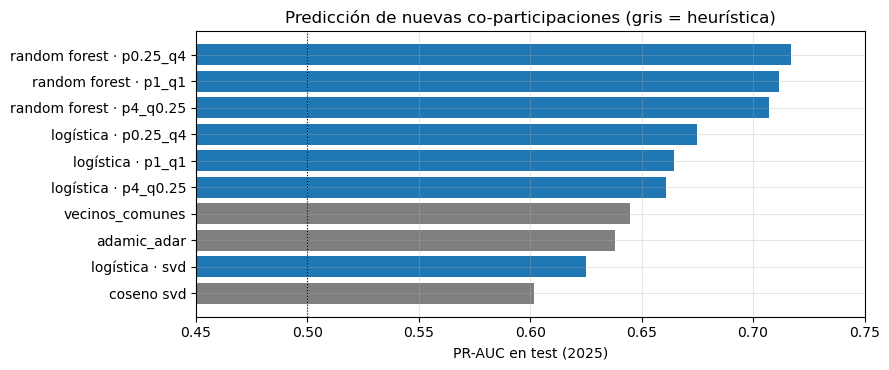

,negativos,roc_auc,roc_auc_adamic_adar
0,neg al azar,0.8854,0.8322
1,neg 2 saltos,0.5948,0.4310


In [7]:
mejor_por = (res.assign(familia=np.where(res.modelo == "base", res.config, res.modelo + " · " + res.config))
                .sort_values("pr_auc", ascending=False).drop_duplicates("familia").head(10))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(mejor_por.familia[::-1], mejor_por.pr_auc[::-1], color=["tab:gray" if m == "base" else "tab:blue" for m in mejor_por.modelo[::-1]])
ax.axvline(.5, color="k", ls=":", lw=.8)
ax.set(xlim=(.45, .75), xlabel="PR-AUC en test (2025)", title="Predicción de nuevas co-participaciones (gris = heurística)")
mostrar_fig("enlaces_resumen")
por_tipo

In [8]:
prec_top

,top,% aparece en 2025
0,30,13.33
1,100,11.00
2,1000,7.10
3,10000,5.16
4,300000,1.32


- **El embedding anticipa nuevas co-participaciones** mejor que las heurísticas (PR-AUC 0.72 vs 0.64), con evaluación temporal sin fuga

- **Su ventaja está en el caso difícil:** entre pares que ya comparten un competidor, Adamic-Adar no discrimina (0.43) y el embedding sí (0.60)

- **Utilidad práctica limitada y honesta:** en el top 30 solo el 13% aparece en 2025; es un ×10 sobre la base, pero la mayoría de las predicciones no se concreta en un año

- El mercado se renueva mucho (73-78% de aristas nuevas por año): ningún modelo puede anticipar bien a quién se le ocurrirá ofertar

---
### **4. Preguntas de interés**

**PQ2 – ¿Qué mercados emergen de la co-participación? ¿Son regionales o por rubro?**

- **Por rubro primero, por región después:** el NMI con el segmento (0.37) triplica al de la región (0.12)

- Seis mercados estables: obras civiles, consultoría de ingeniería, alimentos y combustibles, bienes diversos en Lima, servicios de construcción en Lima y el **sur andino** (Cusco, Puno, Ayacucho, Apurímac)

- El sur andino es el único mercado definido sobre todo por geografía: obras + materiales de construcción de proveedores locales

- **Obras y consultoría** tienen la menor fracción de proveedores que alguna vez ganan (33-34%): mercados con mucha oferta por adjudicación

**PQ3 – ¿Qué proveedores son alternativas y qué afinidades son inusuales?**

- Los **vecinos del embedding** son sustitutos por posición: compiten en los mismos procesos que los mismos competidores (p. ej., consultores 8110 de Áncash)

- Los **enlaces predichos** apuntan a sustitutos que aún no se cruzaron: sobre todo **distribuidores farmacéuticos y de insumos médicos de Lima**

- Esto complementa los sustitutos por ALS y contenido de `03_Recomend` (desde el lado entidad–proveedor) con el lado proveedor–proveedor

---
### **5. Variación de los resultados**

| Parámetro | Rango probado | Efecto |
|---|---|---|
| Hubs retirados (`PCT_HUB`) | 0-1% | Con 0.1% se van los postores masivos (11.4% de la masa); más allá se pierde un tercio de las aristas |
| Dimensión | 32, 64, 128 | 32 separa mejor los pares futuros (AUC 0.879 vs 0.853) |
| p, q | 0.25-4 | ±3 puntos de homofilia y ±0.03 de rol; PR-AUC ±0.01; del orden del ruido entre semillas |
| Semilla | 42 vs 7 | Comparten 28% de los 10 vecinos, pero el perfil agregado es el mismo |
| `n_neighbors` UMAP | 15, 30, 50 | Confiabilidad 0.979-0.985: la proyección es robusta |
| *k* latente | 4-20 | Estable (ARI 0.99) hasta k = 6; desde 8 el corte es arbitrario |
| Operador de par | Hadamard, L1, L2 | Solo Hadamard supera a las heurísticas |

---
### **6. Encuadre ético**

- **Todo lo que muestra esta parte es descriptivo:** cercanía en el embedding, grupos latentes y enlaces predichos son **afinidades estructurales** derivadas de quién oferta en los mismos procesos

- **No son evidencia de colusión, acuerdo ni irregularidad.** Que dos proveedores estén cerca o "deberían" competir se explica de muchas formas legítimas: mismo rubro, misma región, especialización, capacidad

- **Postores masivos (hubs retirados):** ofertan a miles de procesos y casi no ganan; es un **patrón de oferta**, no una conducta sospechosa por sí misma

- **Uso responsable:** describir la estructura del mercado y, a lo sumo, **priorizar una revisión humana** con información que el OCDS no tiene (contratos, bases, ejecución)

- **Personas naturales (`PN:`):** contienen el DNI en la clave; solo se publican nombres ya públicos en el OCDS y agregados

---
### **7. Síntesis**

| Pregunta | Hallazgo |
|---|---|
| ¿Qué técnica? | Node2Vec (grilla p × q, 32 dimensiones) sobre co-participación sin postores masivos; SVD como referencia lineal |
| ¿Qué capturan? | **Mercado** (rubro, luego región) y en menor medida **rol**; p y q casi no cambian el resultado por la estructura de cliques |
| ¿Convergen con la Parte II? | Poco (NMI ≈ 0.09): posición en el mercado vs comportamiento; solo coinciden en obras |
| ¿Y con la Parte IV? | Ortogonales: el embedding dice dónde compite un proveedor, PageRank cuánto pesa |
| ¿Y con la Parte V? | Alta (NMI 0.77 a igual k): las comunidades se anidan en los 6 mercados latentes |
| ¿Sirven para predecir? | Sí, mejor que las heurísticas (PR-AUC 0.72 vs 0.64), sobre todo en pares difíciles; con precisión absoluta baja |
| ¿PQ2? | Mercados por rubro y luego región; el sur andino como mercado regional |
| ¿PQ3? | Sustitutos por posición y pares afines que aún no compiten (salud en Lima) |

---
### **8. Escritura de resultados**

- `hallazgos_web`: los tres hallazgos interactivos y qué artefacto lee la web para cada uno

In [9]:
hallazgos_web = pd.DataFrame([
    {"hallazgo": "Mercados en el espacio latente", "pregunta": "PQ2", "control": "p, q de Node2Vec y k de KMeans",
     "artefacto": "c_proyeccion/web/umap_web.json + nodos_web.json"},
    {"hallazgo": "Qué capturan p y q (homofilia vs rol)", "pregunta": "PQ2", "control": "p, q",
     "artefacto": "b_node2vec/web/perfil_pq.json"},
    {"hallazgo": "Pares afines que aún no compiten", "pregunta": "PQ3", "control": "top-N y umbral de probabilidad",
     "artefacto": "d_enlaces/web/top_pares.json + precision_top.json"}])
escritos = guardar_tablas({"convergencia_ref": ref.reset_index(), "enlaces_resumen": mejor_por, "hallazgos_web": hallazgos_web})

Escrito en 06_Embeddings/temp/e_analisis/: convergencia_ref, enlaces_resumen, hallazgos_web


#### a. Verificación

In [10]:
verificar_salidas(escritos)

OK: 3 tablas (parquet + json) | 3 figuras: convergencia_resumen, enlaces_resumen, homofilia_vs_rol


---
### **9. Cerrar sesión**

In [11]:
spark.stop()